**Objetivo del proyecto:**
Desarrollar un modelo de Machine Learning capaz de identificar las señales de deterioro de los discos de almacenamiento de un centro de datos y estimar la probabilidad de que fallen en los próximos 30 días, permitiendo actuar antes de que suceda.

## 1. Comprensión del problema y elección de la métrica

*El punto de partida es facilitar al equipo de operaciones de un centro de datos saber qué discos tienen una probabilidad alta de fallar pronto, para cambiarlos antes de que provoquen una avería. Target: ¿falla el disco en los próximos 30 días?*

*La respuesta es una categoría con dos valores (1 = falla, 0 = no falla): es un problema de **clasificación binaria**.*

*El error más costoso es el **falso negativo**: que el modelo diga «sano» y el disco falle. Provoca una avería por sorpresa y puede detener el servicio (una caída grave cuesta más de 100.000 $, según el Uptime Institute 2026). El **falso positivo** (revisar un disco que estaba sano) es más barato.*

*Por eso la métrica principal es el **recall de la clase 1** (de todos los discos que fallan, cuántos se detectan). Se tiene en cuenta también la **precisión** (de todas las alarmas, cuántas son reales) para no saturar al equipo con falsas alarmas.*

*Las clases no estarán equilibradas: en una flota real falla en torno al 1-2 % de los discos al año. Por eso:*
- *la **accuracy no sirve** (decir siempre «sano» acertaría casi siempre sin detectar ningún fallo);*
- *para comparar modelos se usa **PR-AUC** (`average_precision`), que resume precisión y recall sin depender del umbral y es la recomendada cuando la clase positiva es rara (documentación de scikit-learn, 3.4 Metrics and scoring).*

*La predicción se traducirá en dos acciones con costes distintos: **vigilar** un disco (revisarlo y comprobar las copias) es barato, así que ahí prima detectar muchos fallos (recall); **sustituirlo** cuesta dinero, así que ahí prima que la alarma sea real (precisión). Por eso el modelo dará una probabilidad y se elegirán **dos umbrales** con validación cruzada, nunca con el test.*

## Imports y datos de entrenamiento

*Leo train y test tal como los dejé en el notebook 02, y las listas de variables desde el JSON. Además de X e y guardo los grupos: el número de serie de cada fila. Se los paso a toda la validación cruzada para que un mismo disco no caiga en dos pliegues; si lo hiciera, el modelo se examinaría con discos que ya conoce.*

In [1]:
import os
import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, GridSearchCV, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, recall_score,
                             precision_score, average_precision_score, silhouette_score, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from scipy.stats import ttest_rel
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

target = "falla_30d"
train_set = pd.read_csv("data/train/train.csv", low_memory = False)
test_set = pd.read_csv("data/test/test.csv", low_memory = False)
with open("data/processed/conjuntos_variables.json") as f:
    info = json.load(f)
conjuntos = info["conjuntos"]
features_cat = info["categoricas"]
reducido = conjuntos["reducido"]

X_train = train_set[reducido + features_cat]
y_train = train_set[target]
X_test = test_set[reducido + features_cat]
y_test = test_set[target]
grupos = train_set["serial_number"]          # para que un mismo disco no caiga en dos pliegues
print("X_train:", X_train.shape, "| X_test:", X_test.shape, "| discos en train:", grupos.nunique())

X_train: (20760, 17) | X_test: (5163, 17) | discos en train: 18671


## Preprocesado dentro de un pipeline

*Relleno los huecos con la mediana, aplico log(1 + x) a las variables muy asimétricas y escalo solo para los modelos que lo necesitan (regresión logística, KNN, SVM). El fabricante y el datacenter pasan a One-Hot. Lo meto todo en un pipeline para que, en cada pliegue, la mediana y el escalado se calculen solo con la parte de entrenamiento.*

In [2]:
asimetria = train_set[conjuntos["todas"]].skew()
asimetricas_todas = list(asimetria[asimetria > 1].index)
print("Numéricas muy asimétricas (skew > 1):", len(asimetricas_todas), "de", len(conjuntos["todas"]))

def crear_preprocesado(lista_num, escalar):
    asimetricas = [c for c in lista_num if c in asimetricas_todas]
    resto = [c for c in lista_num if c not in asimetricas_todas]
    pasos_asim = [("imputar", SimpleImputer(strategy = "median")),
                  ("log", FunctionTransformer(np.log1p, feature_names_out = "one-to-one"))]
    pasos_resto = [("imputar", SimpleImputer(strategy = "median"))]
    if escalar:
        pasos_asim.append(("escalar", StandardScaler()))
        pasos_resto.append(("escalar", StandardScaler()))
    return ColumnTransformer([("num_asimetricas", Pipeline(pasos_asim), asimetricas),
                              ("num_resto", Pipeline(pasos_resto), resto),
                              ("cat", OneHotEncoder(handle_unknown = "ignore"), features_cat)])

crear_preprocesado(reducido, escalar = True)

Numéricas muy asimétricas (skew > 1): 41 de 46


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_asimetricas', ...), ('num_resto', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name

## Baseline: lo que hay que superar

*Antes de entrenar nada, miro dos referencias. Una es no hacer nada: decir siempre "sano". La otra es la regla que usaría un técnico: avisar si el disco tiene algún sector dañado. Si el modelo no mejora a esta última, no merece la pena.*

In [5]:
regla = ((train_set[["smart_5_raw", "smart_197_raw", "smart_198_raw"]].fillna(0) > 0).any(axis = 1)).astype(int)
print("Regla «algún sector dañado > 0» | recall:", round(recall_score(y_train, regla), 3),
      "| precisión:", round(precision_score(y_train, regla), 3))
print("Siempre «sano» | recall: 0.0 | accuracy:", round(1 - y_train.mean(), 3))

Regla «algún sector dañado > 0» | recall: 0.659 | precisión: 0.568
Siempre «sano» | recall: 0.0 | accuracy: 0.894


*Decir siempre "sano" acierta el 89 % y no detecta ni un fallo: por eso la accuracy no sirve aquí. La regla del técnico detecta el 66 % de los fallos, pero solo el 57 % de sus avisos son reales. Esa es la marca que el modelo tiene que superar.*

## Modelos y validación cruzada agrupada por disco

*Pruebo ocho modelos supervisados, de los más sencillos a los de boosting. Todos tienen en cuenta que solo falla el 11 %: les doy más peso a los fallos (class_weight o su equivalente).*

*Para validar uso StratifiedGroupKFold con 5 pliegues. Cada pliegue mantiene el mismo porcentaje de fallos y nunca reparte las filas de un mismo disco entre dos pliegues. Mido recall, precisión y, sobre todo, PR-AUC, que resume cómo de bien ordena el modelo los discos de más a menos riesgo.*

In [6]:
peso_positivos = (y_train == 0).sum() / (y_train == 1).sum()
modelos = {
    "Regresion Logistica L1": (LogisticRegression(l1_ratio = 1, solver = "liblinear", class_weight = "balanced", max_iter = 1000, random_state = 42), True),
    "KNN": (KNeighborsClassifier(n_neighbors = 15), True),
    "SVM": (SVC(class_weight = "balanced", random_state = 42), True),
    "Arbol de decision": (DecisionTreeClassifier(max_depth = 6, class_weight = "balanced", random_state = 42), False),
    "Random Forest": (RandomForestClassifier(max_depth = 10, class_weight = "balanced", n_jobs = 1, random_state = 42), False),
    "XGBoost": (XGBClassifier(max_depth = 6, scale_pos_weight = peso_positivos, n_jobs = 1, random_state = 42, verbosity = 0), False),
    "LightGBM": (LGBMClassifier(max_depth = 6, class_weight = "balanced", n_jobs = 1, random_state = 42, verbose = -1), False),
    "CatBoost": (CatBoostClassifier(depth = 6, auto_class_weights = "Balanced", thread_count = 1, random_state = 42, verbose = 0, allow_writing_files = False), False),
}
# el booleano indica si el modelo necesita escalar (distancias, penalización o varianza)

def crear_pipeline(nombre, lista_num):
    modelo, escalar = modelos[nombre]
    return Pipeline([("preprocesado", crear_preprocesado(lista_num, escalar)), ("modelo", clone(modelo))])

cv = StratifiedGroupKFold(n_splits = 5, shuffle = True, random_state = 42)
scoring = {"recall": "recall", "precision": "precision", "pr_auc": "average_precision"}

## Comparativa de modelos

*Comparo los ocho modelos y un noveno no supervisado + supervisado (PCA a 10 componentes y después Random Forest). Todos con los mismos pliegues y la misma métrica, para que la comparación sea justa.*

,modelo,recall,precision,pr_auc,pr_auc_std
6,LightGBM,0.711,0.582,0.706,0.037
4,Random Forest,0.704,0.643,0.704,0.035
7,CatBoost,0.694,0.581,0.696,0.039
8,PCA + Random Forest,0.689,0.626,0.693,0.033
0,Regresion Logistica L1,0.707,0.511,0.676,0.045
5,XGBoost,0.615,0.584,0.657,0.039
1,KNN,0.522,0.798,0.643,0.038
3,Arbol de decision,0.704,0.537,0.630,0.041
2,SVM,0.729,0.584,0.545,0.030


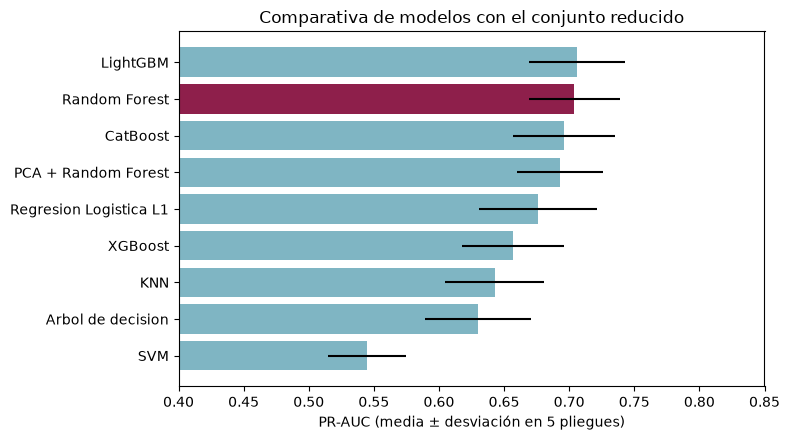

In [8]:
resultados = []
for nombre in modelos:
    cv_res = cross_validate(crear_pipeline(nombre, reducido), X_train, y_train, cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
    resultados.append([nombre, cv_res["test_recall"].mean(), cv_res["test_precision"].mean(),
                       cv_res["test_pr_auc"].mean(), cv_res["test_pr_auc"].std()])
pca_rf = Pipeline([("preprocesado", crear_preprocesado(reducido, escalar = True)),
                   ("pca", PCA(n_components = 10, random_state = 42)),
                   ("modelo", RandomForestClassifier(max_depth = 10, class_weight = "balanced", random_state = 42))])
cv_res = cross_validate(pca_rf, X_train, y_train, cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
resultados.append(["PCA + Random Forest", cv_res["test_recall"].mean(), cv_res["test_precision"].mean(),
                   cv_res["test_pr_auc"].mean(), cv_res["test_pr_auc"].std()])

comparativa = pd.DataFrame(resultados, columns = ["modelo", "recall", "precision", "pr_auc", "pr_auc_std"])
comparativa = comparativa.sort_values("pr_auc").round(3)
plt.figure(figsize = (8, 4.5))
plt.barh(comparativa["modelo"], comparativa["pr_auc"], xerr = comparativa["pr_auc_std"],
         color = ["#8E1F4B" if m == "Random Forest" else "#7FB5C3" for m in comparativa["modelo"]])   # ← cambiado
plt.xlim(0.4, 0.85)
plt.xlabel("PR-AUC (media ± desviación en 5 pliegues)")
plt.title("Comparativa de modelos con el conjunto reducido")
plt.tight_layout()
comparativa.sort_values("pr_auc", ascending = False)

*LightGBM (0,706), Random Forest (0,704) y CatBoost (0,696) quedan arriba; la regresión logística, en 0,676. Todos mejoran mucho al azar, que estaría en 0,11 (la proporción de fallos). La desviación entre pliegues (±0,04) es mayor que las diferencias entre los primeros, pero eso no significa que empaten: la desviación mide sobre todo que unos pliegues son más difíciles que otros para todos los modelos a la vez. Para saber si uno gana de verdad, hay que compararlos pliegue a pliegue.*

## Comparación pareada: pliegue a pliegue

*Las barras de error se solapan, pero eso no basta para decir que hay empate. Todos los modelos se han validado con los mismos 5 pliegues, así que comparo cada pliegue por separado y aplico un t-test pareado. Lo hago con los dos candidatos más fuertes (Random Forest y LightGBM) y con la regresión logística, el modelo sencillo de referencia.*

In [9]:
# Mismos 5 pliegues para todos: comparo pliegue a pliegue (comparación pareada)
por_pliegue = {}
for nombre in ["Regresion Logistica L1", "Random Forest", "LightGBM"]:
    cv_res = cross_validate(crear_pipeline(nombre, reducido), X_train, y_train, cv = cv,
                            scoring = "average_precision", groups = grupos, n_jobs = -1)
    por_pliegue[nombre] = cv_res["test_score"]
por_pliegue = pd.DataFrame(por_pliegue, index = ["pliegue " + str(k) for k in range(1, 6)])
por_pliegue["RF - LogReg"] = por_pliegue["Random Forest"] - por_pliegue["Regresion Logistica L1"]
por_pliegue["RF - LightGBM"] = por_pliegue["Random Forest"] - por_pliegue["LightGBM"]
print("t-test pareado RF vs regresión logística: p =", round(ttest_rel(por_pliegue["Random Forest"], por_pliegue["Regresion Logistica L1"]).pvalue, 3))
print("t-test pareado RF vs LightGBM: p =", round(ttest_rel(por_pliegue["Random Forest"], por_pliegue["LightGBM"]).pvalue, 3))
por_pliegue.round(3)

t-test pareado RF vs regresión logística: p = 0.042
t-test pareado RF vs LightGBM: p = 0.307


,Regresion Logistica L1,Random Forest,LightGBM,RF - LogReg,RF - LightGBM
pliegue 1,0.642,0.665,0.669,0.023,-0.004
pliegue 2,0.739,0.734,0.741,-0.005,-0.006
pliegue 3,0.654,0.705,0.701,0.051,0.004
pliegue 4,0.720,0.750,0.756,0.030,-0.006
pliegue 5,0.624,0.663,0.663,0.039,0.001


*Random Forest supera a la regresión logística en 4 de los 5 pliegues, por 0,03 de media, y la diferencia es significativa (p = 0,04). Frente a LightGBM, la diferencia en cada pliegue no pasa de ±0,006 (p = 0,31): empatan. Me quedo con Random Forest. Rinde igual que el mejor, tiene mejor precisión, pocos hiperparámetros que ajustar y es más fácil de explicar que un boosting.*

## ¿Qué conjunto de variables usa el ganador?

*Con Random Forest ya elegido, pruebo los tres conjuntos que preparé en el notebook 02: todas las variables (46), sin las poco útiles (28) y el reducido (15). Si empatan, me quedo con el más pequeño: es más rápido y la app pedirá menos datos.*

In [10]:
ganador = "Random Forest"
res = []
for nombre, lista in conjuntos.items():
    cv_res = cross_validate(crear_pipeline(ganador, lista), train_set[lista + features_cat], y_train,
                            cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
    res.append([nombre, len(lista), cv_res["test_pr_auc"].mean(), cv_res["test_pr_auc"].std(),
                cv_res["test_recall"].mean(), cv_res["test_precision"].mean()])
tabla_conjuntos = pd.DataFrame(res, columns = ["conjunto", "n_variables", "pr_auc", "pr_auc_std", "recall", "precision"])
# Las diferencias son menores que la desviación entre pliegues: me quedo con el conjunto más sencillo
variables = conjuntos["reducido"]
X_train = train_set[variables + features_cat]
X_test = test_set[variables + features_cat]
tabla_conjuntos.round(3)

,conjunto,n_variables,pr_auc,pr_auc_std,recall,precision
0,todas,46,0.713,0.033,0.713,0.648
1,sin_poco_utiles,28,0.703,0.033,0.709,0.641
2,reducido,15,0.704,0.035,0.704,0.643


*Los tres conjuntos quedan a menos de 0,01 entre sí, muy por debajo de la variación entre pliegues (±0,03): empate. Me quedo con el reducido. Con 15 variables rinde igual que con 46, entrena más rápido y en la app hay que rellenar menos campos.*

## GridSearchCV: ajustar el Random Forest

*Busco la mejor combinación de profundidad, tamaño mínimo de las hojas y pesos de clase. Mido tres métricas a la vez, pero elijo por PR-AUC (refit = "pr_auc"). Guardo también la nota en entrenamiento para vigilar el sobreajuste. Los pesos de clase entran en la rejilla como un hiperparámetro más, así que la propia búsqueda decide si hace falta balancear.*

In [11]:
scoring_grid = {"pr_auc": "average_precision", "recall": "recall", "precision": "precision"}
grid = GridSearchCV(crear_pipeline(ganador, variables),
                    param_grid = {"modelo__n_estimators": [300],
                                  "modelo__max_depth": [12, None],
                                  "modelo__min_samples_leaf": [1, 5, 20],
                                  "modelo__class_weight": [None, "balanced", "balanced_subsample"]},
                    cv = cv, scoring = scoring_grid, refit = "pr_auc", return_train_score = True,
                    n_jobs = -1, verbose = 2)
grid.fit(X_train, y_train, groups = grupos)
print("Mejores parámetros:", grid.best_params_)
print("PR-AUC en validación cruzada:", round(grid.best_score_, 3))
columnas = ["param_modelo__max_depth", "param_modelo__min_samples_leaf", "param_modelo__class_weight",
            "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "mean_test_recall", "mean_test_precision"]
pd.DataFrame(grid.cv_results_)[columnas].astype({"param_modelo__class_weight": str, "param_modelo__max_depth": str}).sort_values("mean_test_pr_auc", ascending = False).head(6).round(3)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Mejores parámetros: {'modelo__class_weight': None, 'modelo__max_depth': 12, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}
PR-AUC en validación cruzada: 0.725


,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__class_weight,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc,mean_test_recall,mean_test_precision
1,12,5,NaN,0.846,0.725,0.041,0.526,0.822
0,12,1,NaN,0.889,0.724,0.041,0.516,0.826
2,12,20,NaN,0.793,0.721,0.039,0.518,0.817
5,NaN,20,NaN,0.816,0.719,0.039,0.521,0.817
4,NaN,5,NaN,0.917,0.718,0.042,0.537,0.814
8,12,20,balanced,0.796,0.715,0.036,0.736,0.576


*Gana max_depth = 12, min_samples_leaf = 5 y sin pesos de clase, con una PR-AUC de 0,725. En entrenamiento saca 0,85 y en validación 0,73: hay algo de sobreajuste, pero controlado. Sin límite de profundidad, el entrenamiento sube a 0,92 y la validación no mejora. Sin pesos de clase, con el umbral por defecto (0,5) solo detecta el 53 % de los fallos, pero eso lo arreglo más adelante eligiendo el umbral.*

## ¿Qué conjunto de variables usa el ganador?

*Con Random Forest ya elegido, pruebo los tres conjuntos que preparé en el notebook 02: todas las variables (46), sin las poco útiles (28) y el reducido (15). Si empatan, me quedo con el más pequeño: es más rápido y la app pedirá menos datos.*

In [12]:
ganador = "Random Forest"
res = []
for nombre, lista in conjuntos.items():
    cv_res = cross_validate(crear_pipeline(ganador, lista), train_set[lista + features_cat], y_train,
                            cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
    res.append([nombre, len(lista), cv_res["test_pr_auc"].mean(), cv_res["test_pr_auc"].std(),
                cv_res["test_recall"].mean(), cv_res["test_precision"].mean()])
tabla_conjuntos = pd.DataFrame(res, columns = ["conjunto", "n_variables", "pr_auc", "pr_auc_std", "recall", "precision"])
# Las diferencias son menores que la desviación entre pliegues: me quedo con el conjunto más sencillo
variables = conjuntos["reducido"]
X_train = train_set[variables + features_cat]
X_test = test_set[variables + features_cat]
tabla_conjuntos.round(3)

,conjunto,n_variables,pr_auc,pr_auc_std,recall,precision
0,todas,46,0.713,0.033,0.713,0.648
1,sin_poco_utiles,28,0.703,0.033,0.709,0.641
2,reducido,15,0.704,0.035,0.704,0.643


*Los tres conjuntos quedan a menos de 0,01 entre sí, muy por debajo de la variación entre pliegues (±0,03): empate. Me quedo con el reducido. Con 15 variables rinde igual que con 46, entrena más rápido y en la app hay que rellenar menos campos.*

## GridSearchCV: ajustar el Random Forest

*Busco la mejor combinación de profundidad, tamaño mínimo de las hojas y pesos de clase. Mido tres métricas a la vez, pero elijo por PR-AUC (refit = "pr_auc"). Guardo también la nota en entrenamiento para vigilar el sobreajuste. Los pesos de clase entran en la rejilla como un hiperparámetro más, así que la propia búsqueda decide si hace falta balancear.*

In [14]:
scoring_grid = {"pr_auc": "average_precision", "recall": "recall", "precision": "precision"}
grid = GridSearchCV(crear_pipeline(ganador, variables),
                    param_grid = {"modelo__n_estimators": [300],
                                  "modelo__max_depth": [12, None],
                                  "modelo__min_samples_leaf": [1, 5, 20],
                                  "modelo__class_weight": [None, "balanced", "balanced_subsample"]},
                    cv = cv, scoring = scoring_grid, refit = "pr_auc", return_train_score = True,
                    n_jobs = -1, verbose = 2)
grid.fit(X_train, y_train, groups = grupos)
print("Mejores parámetros:", grid.best_params_)
print("PR-AUC en validación cruzada:", round(grid.best_score_, 3))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Mejores parámetros: {'modelo__class_weight': None, 'modelo__max_depth': 12, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}
PR-AUC en validación cruzada: 0.725


In [16]:
columnas = ["param_modelo__max_depth", "param_modelo__min_samples_leaf", "param_modelo__class_weight",
            "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "mean_test_recall", "mean_test_precision"]
tabla_grid = pd.DataFrame(grid.cv_results_)[columnas]
# None = sin límite / sin pesos. Lo leo de "params" porque pandas convierte None en NaN
for p in ["max_depth", "class_weight"]:
    tabla_grid["param_modelo__" + p] = [str(params["modelo__" + p]) for params in grid.cv_results_["params"]]
tabla_grid.sort_values("mean_test_pr_auc", ascending = False).head(6).round(3)

,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__class_weight,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc,mean_test_recall,mean_test_precision
1,12,5,None,0.846,0.725,0.041,0.526,0.822
0,12,1,None,0.889,0.724,0.041,0.516,0.826
2,12,20,None,0.793,0.721,0.039,0.518,0.817
5,None,20,None,0.816,0.719,0.039,0.521,0.817
4,None,5,None,0.917,0.718,0.042,0.537,0.814
8,12,20,balanced,0.796,0.715,0.036,0.736,0.576


*Gana max_depth = 12, min_samples_leaf = 5 y sin pesos de clase, con una PR-AUC de 0,725. En entrenamiento saca 0,85 y en validación 0,73: hay algo de sobreajuste, pero controlado. Sin límite de profundidad, el entrenamiento sube a 0,92 y la validación no mejora. Sin pesos de clase, con el umbral por defecto (0,5) solo detecta el 53 % de los fallos, pero eso lo arreglo más adelante eligiendo el umbral.*

## Desbalanceo: ¿hace falta tratarlo?

*Solo falla el 11 %, así que comparo cuatro opciones con el Random Forest ya ajustado: no hacer nada, dar más peso a los fallos (class_weight), crear fallos sintéticos (SMOTE) y quitar sanos (undersampling). SMOTE y undersampling van dentro del pipeline de imblearn, para que solo toquen la parte de entrenamiento de cada pliegue y nunca la de validación.*

In [17]:
mejores = grid.best_estimator_.named_steps["modelo"].get_params()
def bosque(class_weight):
    return RandomForestClassifier(n_estimators = 300, max_depth = mejores["max_depth"], min_samples_leaf = mejores["min_samples_leaf"],
                                  class_weight = class_weight, n_jobs = 1, random_state = 42)

prepro = crear_preprocesado(variables, escalar = False)
tecnicas = {"Sin tratar": Pipeline([("preprocesado", prepro), ("modelo", bosque(None))]),
            "class_weight balanced": Pipeline([("preprocesado", prepro), ("modelo", bosque("balanced"))]),
            "SMOTE": ImbPipeline([("preprocesado", prepro), ("smote", SMOTE(random_state = 42)), ("modelo", bosque(None))]),
            "RandomUnderSampler": ImbPipeline([("preprocesado", prepro), ("under", RandomUnderSampler(random_state = 42)), ("modelo", bosque(None))])}
res = []
for nombre, pipe in tecnicas.items():
    cv_res = cross_validate(pipe, X_train, y_train, cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
    res.append([nombre, cv_res["test_recall"].mean(), cv_res["test_precision"].mean(), cv_res["test_pr_auc"].mean()])
pd.DataFrame(res, columns = ["tecnica", "recall", "precision", "pr_auc"]).round(3)

,tecnica,recall,precision,pr_auc
0,Sin tratar,0.526,0.822,0.725
1,class_weight balanced,0.719,0.628,0.713
2,SMOTE,0.666,0.694,0.704
3,RandomUnderSampler,0.742,0.560,0.705


*Las tres técnicas suben el recall con el umbral por defecto (0,5), pero las tres bajan la PR-AUC: ordenan peor los discos de más a menos riesgo. La mejor PR-AUC sale sin tocar las clases. Por eso no balanceo los datos: trato el desbalanceo moviendo el umbral de decisión, que consigue el recall que necesito sin estropear el orden.*

## Curva de aprendizaje: ¿hacían falta más filas?

*Entreno el modelo final con el 20, 40, 60, 80 y 100 % de train y miro cómo cambia la PR-AUC en validación. Si la curva ya fuera plana, más filas no habrían servido de nada; si sigue subiendo, usar unas 26.000 filas en lugar de 5.000 estaba justificado.*

,filas,pr_auc_validacion,desviacion
0,3321,0.692,0.037
1,6642,0.713,0.045
2,9964,0.719,0.042
3,13285,0.723,0.041
4,16607,0.726,0.041


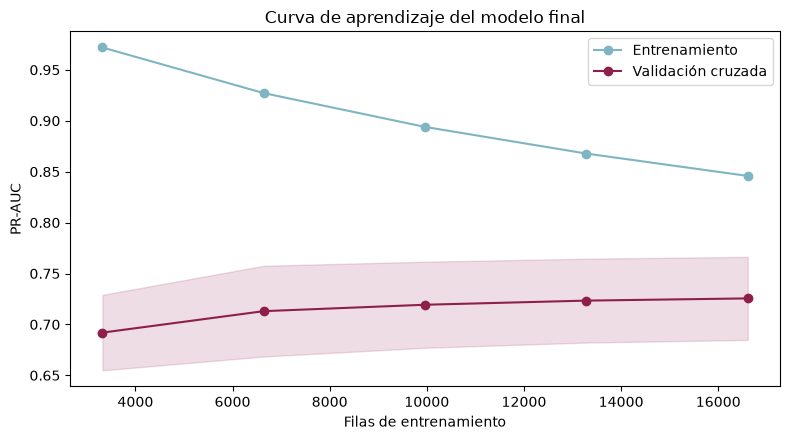

In [18]:
tamanos, train_sc, val_sc = learning_curve(grid.best_estimator_, X_train, y_train, groups = grupos, cv = cv,
                                           scoring = "average_precision", train_sizes = [0.2, 0.4, 0.6, 0.8, 1.0], n_jobs = -1)
plt.figure(figsize = (8, 4.5))
plt.plot(tamanos, train_sc.mean(axis = 1), marker = "o", color = "#7FB5C3", label = "Entrenamiento")
plt.plot(tamanos, val_sc.mean(axis = 1), marker = "o", color = "#8E1F4B", label = "Validación cruzada")
plt.fill_between(tamanos, val_sc.mean(axis = 1) - val_sc.std(axis = 1), val_sc.mean(axis = 1) + val_sc.std(axis = 1), color = "#8E1F4B", alpha = 0.15)
plt.xlabel("Filas de entrenamiento")
plt.ylabel("PR-AUC")
plt.title("Curva de aprendizaje del modelo final")
plt.legend()
plt.tight_layout()
pd.DataFrame({"filas": tamanos, "pr_auc_validacion": val_sc.mean(axis = 1).round(3), "desviacion": val_sc.std(axis = 1).round(3)})

*La validación sube hasta el final: de 0,692 con 3.300 filas a 0,726 con 16.600. Más filas sí ayudan a este modelo, y es el argumento para haber usado unas 26.000 en lugar de 5.000. La subida ya es suave al final, así que añadir muchas más filas daría poco. Las dos líneas se van acercando: con más datos, el modelo memoriza menos y generaliza mejor.*